In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('combined/combined_data.csv')
df = df[df['defect_sites'] != 1.0]
df.head()

,_id,dataset_material,vacancy_sites,substitution_sites,defect_sites,Formation_Energy,band_gap_value,strata
0,BN_B62C2N63_816498e1-eef8-400f-93d4-17a0a435389a,high_BN,1.0,2.0,3.0,20.845103,0.47870,0
1,BN_B62C1N63_631c0dc0-4762-4e3c-93ba-d4876a1b7997,high_BN,2.0,1.0,3.0,44.184872,0.59710,0
2,BN_B63C2N62_5ea09385-eb62-43dc-9334-9142794a8de0,high_BN,1.0,2.0,3.0,24.337552,0.84450,0
3,BN_B63C1N62_e4656f55-37a8-4fcf-bec1-fd7cc833f86b,high_BN,2.0,1.0,3.0,46.783747,0.87055,0
4,BN_B62C2N63_91fe1ce6-6a19-4a26-8caa-82caf4ca6ac2,high_BN,1.0,2.0,3.0,22.421006,1.84640,0


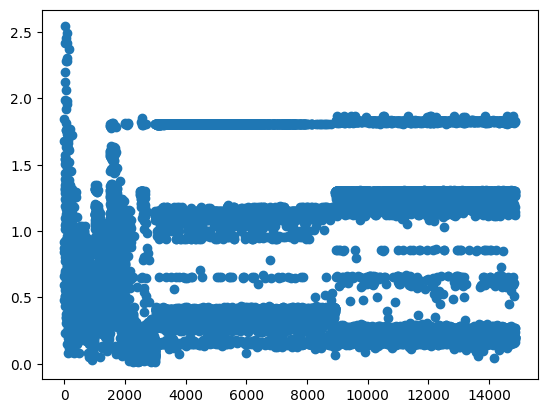

In [2]:
samples = np.arange(len(df))
targets = df['band_gap_value']

plt.scatter(samples, targets)
plt.show()

## What is causing the horizontal bands in the data?

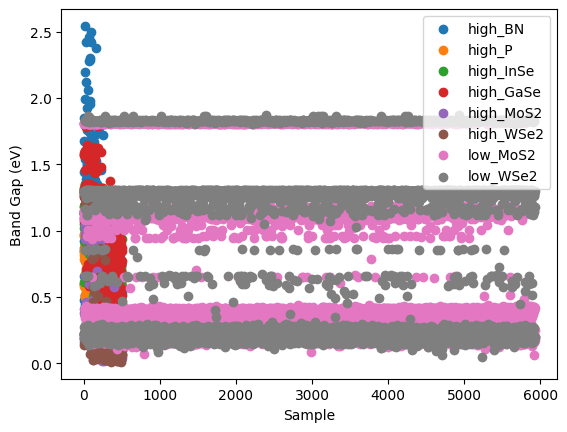

In [3]:
# The type of material?
all_materials = df['dataset_material'].unique()

for material in all_materials:
    df_material = df[df['dataset_material'] == material]

    samples = np.arange(len(df_material))

    plt.scatter(
        samples,
        df_material['band_gap_value'],
        label=material
    )

plt.xlabel('Sample')
plt.ylabel('Band Gap (eV)')
plt.legend()
plt.show()


# Focus on each material

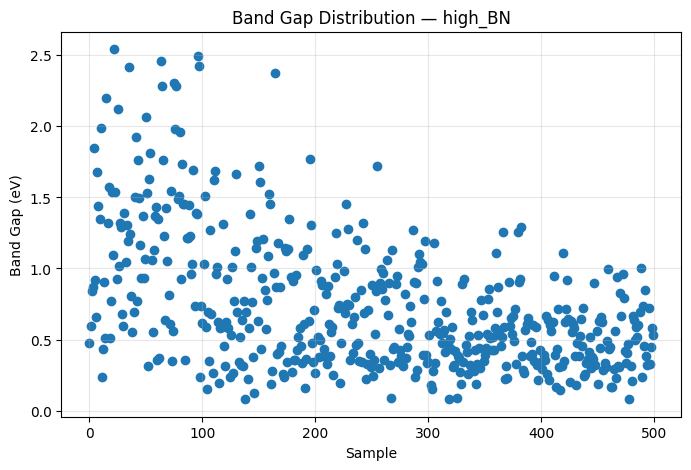

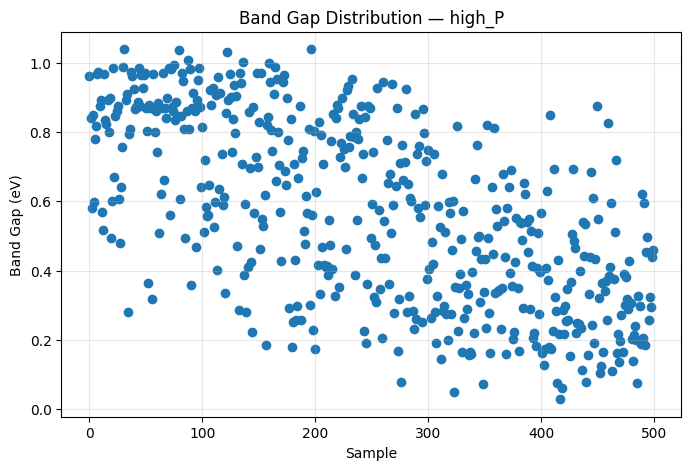

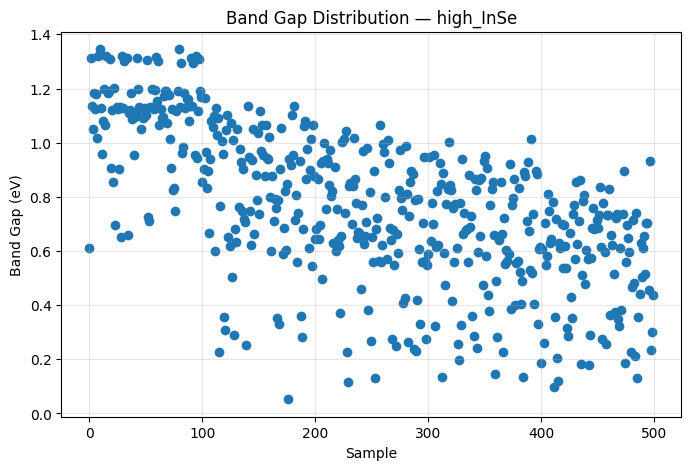

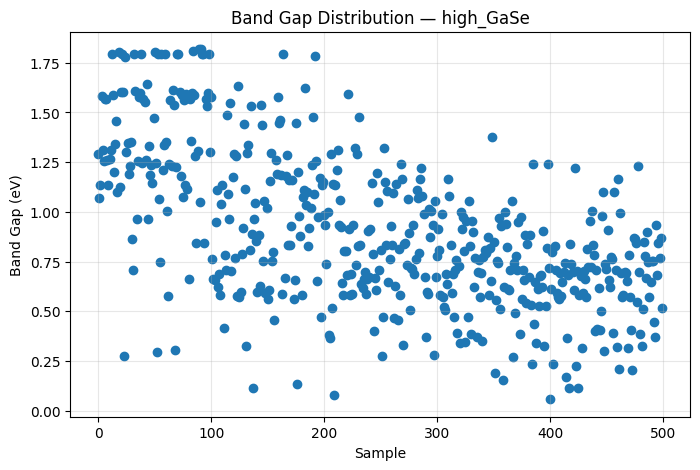

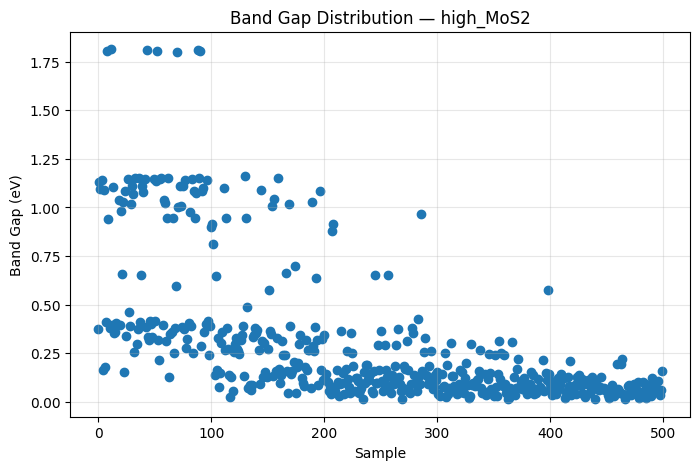

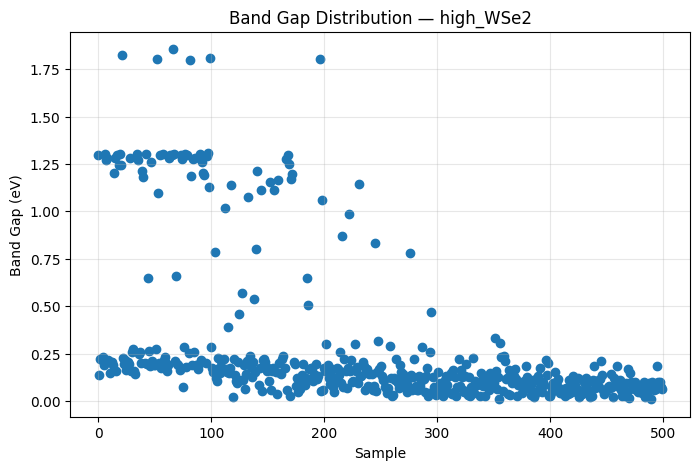

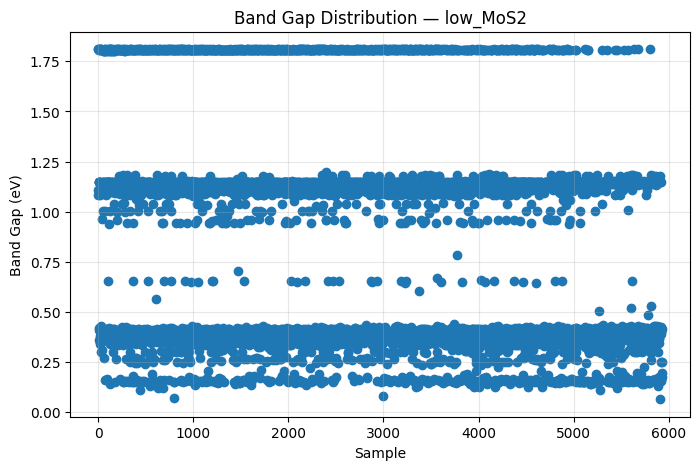

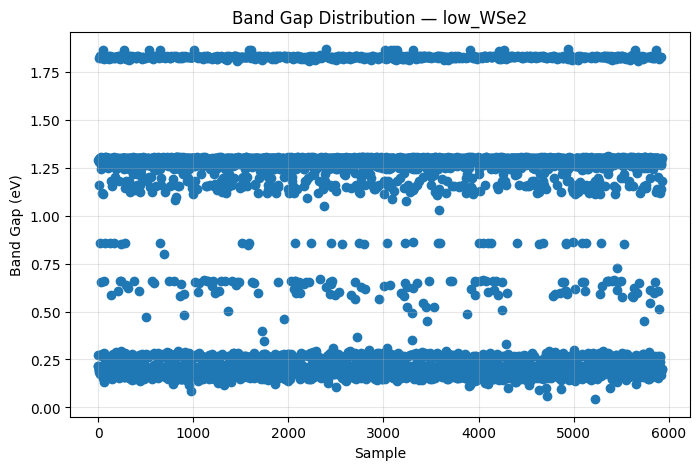

In [4]:
all_materials = df['dataset_material'].unique()

for material in all_materials:
    df_material = df[df['dataset_material'] == material]

    samples = np.arange(len(df_material))
    targets = df_material['band_gap_value']

    plt.figure(figsize=(8, 5))
    plt.scatter(samples, targets)

    plt.title(f'Band Gap Distribution — {material}')
    plt.xlabel('Sample')
    plt.ylabel('Band Gap (eV)')
    plt.grid(alpha=0.3)

    plt.show()

The bands are only forming in MoS2 and WSe2

## Could it be connected to the number of defect sites?

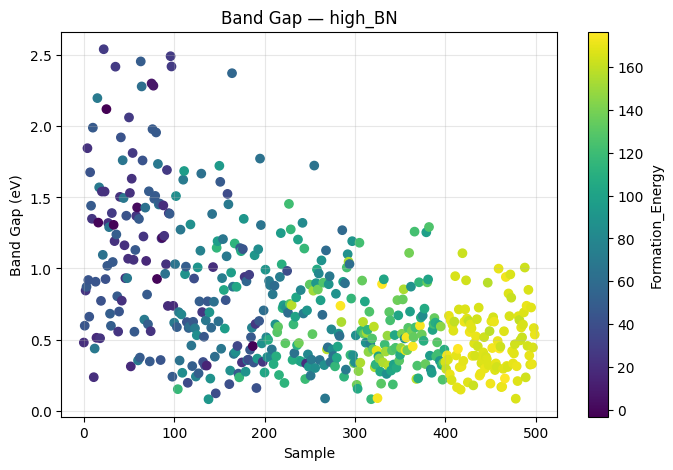

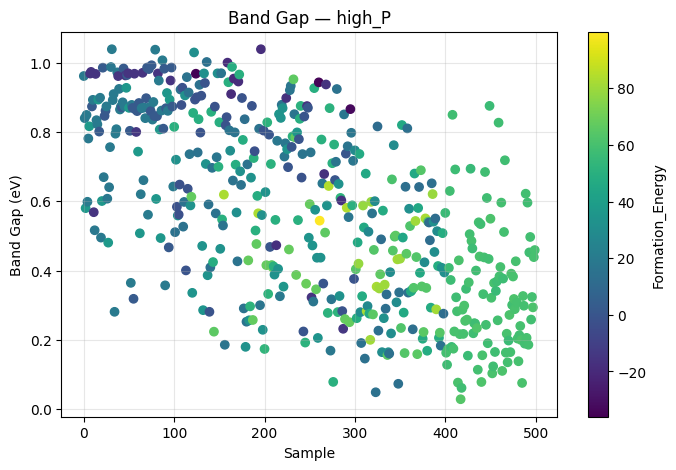

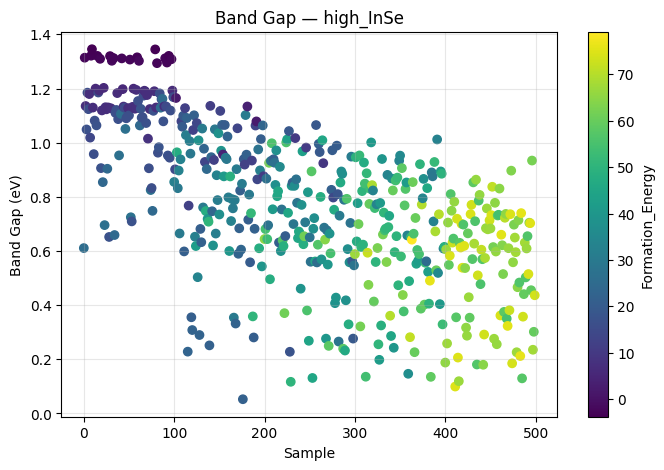

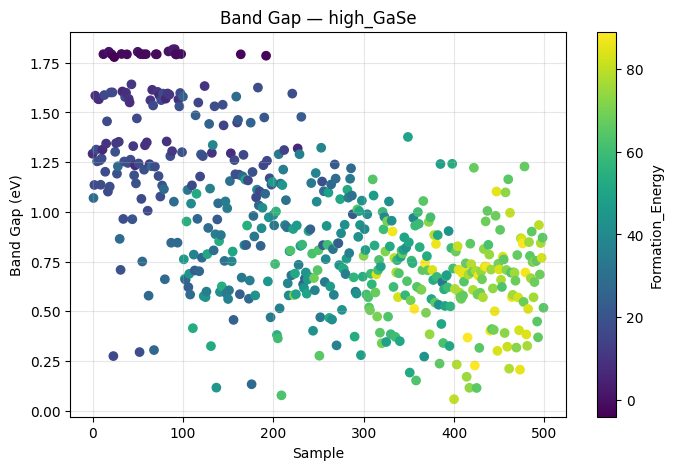

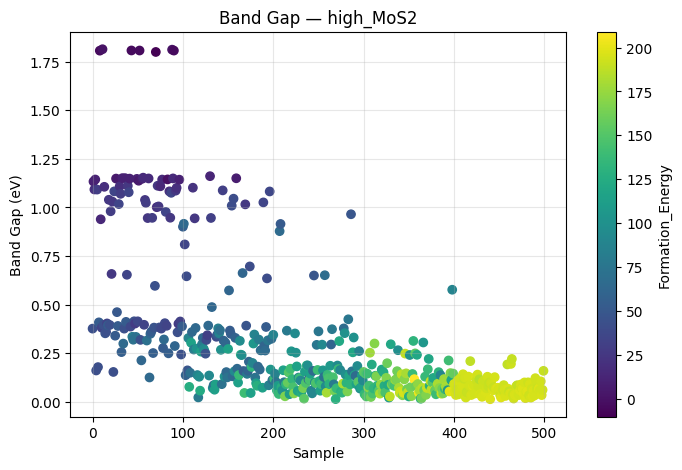

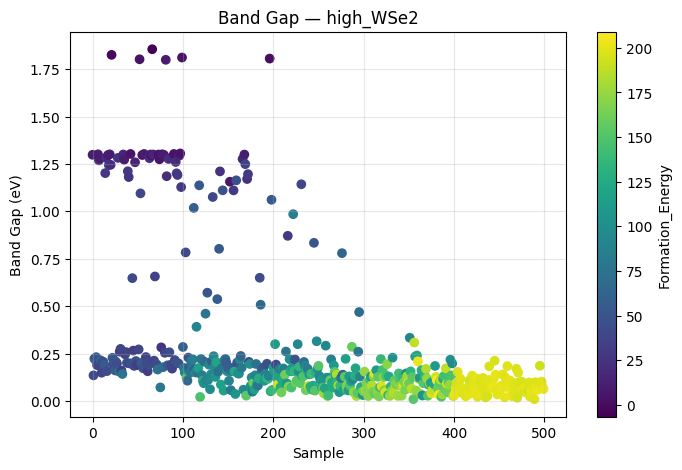

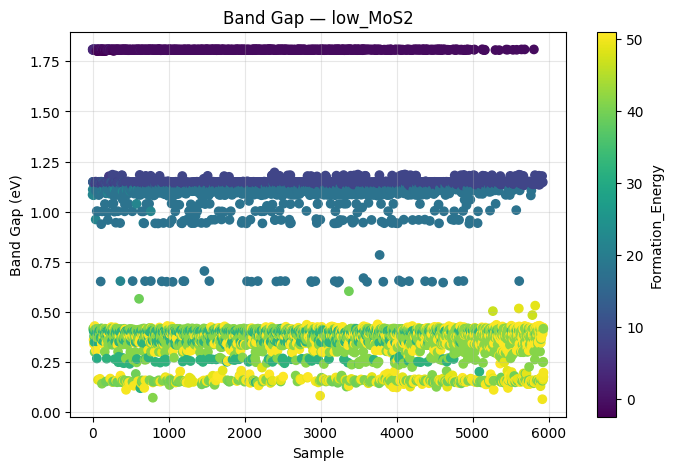

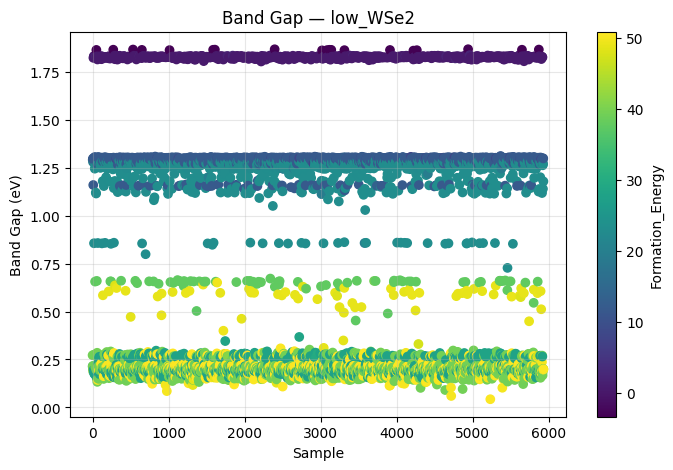

In [5]:
all_materials = df['dataset_material'].unique()
support_attr = 'Formation_Energy'

for material in all_materials:
    df_material = df[df['dataset_material'] == material]

    samples = np.arange(len(df_material))
    band_gap = df_material['band_gap_value']
    x = df_material[support_attr]

    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        samples,
        band_gap,
        c=x,
        cmap='viridis'
    )

    plt.colorbar(scatter, label=support_attr)

    plt.title(f'Band Gap — {material}')
    plt.xlabel('Sample')
    plt.ylabel('Band Gap (eV)')
    plt.grid(alpha=0.3)

    plt.show()

How does this information help explain the results?

Well, there model is learning to predict the same value bacause the bands present are overwhelming the predictions. 

I will tackle this by looking at the bands as the same value in that. I will take the values with the same number of defects, the same region of band gap and have a close formation energy. These structures will be treated as the same even though their structures are not alike. The underlying issue is that these structures produce the same physical properties even though they are different. 

In [7]:
# We will keep the high density data
# Only filter the low density data in this way

low_mos2_df = df[df['dataset_material'] == 'low_MoS2']
low_wse2_df = df[df['dataset_material'] == 'low_WSe2']

low_df = pd.concat([low_wse2_df, low_mos2_df], ignore_index=True)
low_df.head()


,_id,dataset_material,vacancy_sites,substitution_sites,defect_sites,Formation_Energy,band_gap_value,strata
0,619cdd5145851b2ed2430ebf,low_WSe2,2.0,1.0,3.0,39.339326,0.2722,33
1,619cdd5145851b2ed2430ec0,low_WSe2,1.0,2.0,3.0,28.049907,0.2137,33
2,619cdd5145851b2ed2430ec1,low_WSe2,1.0,2.0,3.0,11.772906,1.2913,33
3,619cdd5145851b2ed2430ec2,low_WSe2,2.0,1.0,3.0,39.227761,0.2164,33
4,619cdd5145851b2ed2430ec3,low_WSe2,2.0,1.0,3.0,39.230991,0.2024,33


/tmp/ipykernel_1786490/2056631871.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


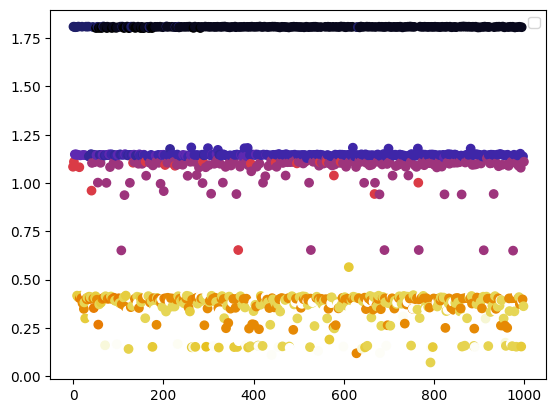

In [12]:
num=1000
low_mos2_1000 = low_mos2_df.head(num)

samples = np.arange(num)
bgs = low_mos2_1000['band_gap_value']

plt.scatter(samples, bgs, c=low_mos2_1000['Formation_Energy'], cmap='CMRmap')
plt.legend()
plt.show()

The above method of getting the first 100o doesnt seem to capture the essence as much. 

Lets try splitting via startification to the band gap

In [16]:
# create band gap bins

# Split into 3 equal-sized groups (tertiles)
low_mos2_df['band gap bins'] = pd.qcut(low_mos2_df['band_gap_value'], q=6)

low_mos2_df.head()


/tmp/ipykernel_1786490/855010229.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  low_mos2_df['band gap bins'] = pd.qcut(low_mos2_df['band_gap_value'], q=6)


,_id,dataset_material,vacancy_sites,substitution_sites,defect_sites,Formation_Energy,band_gap_value,strata,band gap bins
3001,6141cf0f51c1cbd9654b8870,low_MoS2,2.0,0.0,2.0,21.814279,1.0843,31,"(0.657, 1.141]"
3003,6141cf10b842c2e72e2f2d44,low_MoS2,0.0,2.0,2.0,3.131507,1.8095,31,"(1.148, 1.811]"
3004,6141cf1051c1cbd9654b8872,low_MoS2,2.0,0.0,2.0,21.834423,1.1102,31,"(0.657, 1.141]"
3005,6141cf10b842c2e72e2f2d46,low_MoS2,0.0,2.0,2.0,3.132817,1.8093,31,"(1.148, 1.811]"
3006,6141cf11cc0e69a0cf28ab35,low_MoS2,1.0,1.0,2.0,12.473690,1.1484,31,"(1.148, 1.811]"


In [17]:
print(low_mos2_df['band gap bins'].unique())

[(0.657, 1.141], (1.148, 1.811], (1.141, 1.148], (0.401, 0.657], (0.356, 0.401], (0.0625, 0.356]]
Categories (6, interval[float64, right]): [(0.0625, 0.356] < (0.356, 0.401] < (0.401, 0.657] < (0.657, 1.141] < (1.141, 1.148] < (1.148, 1.811]]
